# CoralNet source × binary concept masking candidates

CoralNet sources use different label sets. When a source never uses a label that carries a binary concept (for
example it has no "bleached" labels), every point in that source is a **False** annotation for that concept. Some of
those points may in fact show the concept, but the source simply does not annotate it. The model then learns that the
concept is absent across the whole source.

This notebook flags, for every CoralNet source and every binary concept:

- **only_false**: the source has False annotations for the concept and **no** True ones. These are the masking
  candidates: the source probably does not annotate the concept.
- **only_true**: the source has True annotations and **no** False ones (every annotated point is True).
- **mixed**: both True and False annotations.
- **not_given**: no True or False annotations (every point is `not_given` for the concept, or its label is not in the
  concept table).

Rules and scope:

- Strict: exactly zero True (or zero False) annotations, no tolerance.
- Annotations whose label is `not_given` for the concept, or is not in the concept table, are ignored. They are already
  0 (no loss) in the concept targets.
- All CoralNet splits of `data_config_final_768` (train and test sources).
- Binary concepts: the 39 binary channels of the current model plus `rubble`, `water surface` and `water column`,
  which will be added in the next training code.

It writes `dataset_stats/coralnet_source_concept_mask.parquet` with one row per (source, concept) for later use in
training. No training code is changed.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mermaidseg.dataset_reconciliation.concept_schema import ConceptSchema

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

REPO = Path.cwd().parent if Path.cwd().name == "nbs" else Path.cwd()
CACHE = Path("/archive/vision/beery/red_sea_coral/cache_MERMAID")
LABEL_COUNTS = REPO / "dataset_stats/all_label_counts_final_768.parquet"
CORALNET_MANIFEST = (CACHE / "dev-datamermaid-sm-sources/etl-outputs/coralnet/20260623_nogit/"
                     "coralnet_training_manifest_20260623_nogit.parquet")
CONCEPT_CSV = REPO / "configs/class_to_concepts_v2.csv"
MASK_OUT = REPO / "dataset_stats/coralnet_source_concept_mask.parquet"

RUN_SOURCES = {"coralnet", "mermaid", "coralscapes_v2", "benthos_yuval", "catlin_seaview",
               "moorea_labeled_corals", "pacific_labeled_corals", "ucsd_mosaics"}
EXTRA_BINARY_CONCEPTS = ["rubble", "water surface", "water column"]

## Data

CoralNet rows of the all-splits label counts (`n` = points per image and label), with each image's `source_id` from the
CoralNet manifest.

In [2]:
counts = pd.read_parquet(LABEL_COUNTS)
cn = counts[counts.dataset == "coralnet"].copy()
man = pd.read_parquet(CORALNET_MANIFEST, columns=["source_id", "image_id"]).drop_duplicates("image_id")
cn["source_id"] = cn.image_id.astype(str).map(dict(zip(man.image_id.astype(str), man.source_id.astype(int))))
del man, counts
assert cn.source_id.notna().all()
cn["source_id"] = cn.source_id.astype(int)
assert (cn.groupby("source_id").split.nunique() == 1).all(), "a source appears in more than one split"
source_split = cn.groupby("source_id").split.first()
print(f"{cn.source_id.nunique()} CoralNet sources: {source_split.value_counts().to_dict()}, "
      f"{cn.n.sum():,} points, {cn.label.nunique()} labels")

741 CoralNet sources: {'train': 597, 'test': 144}, 15,526,465 points, 3255 labels


## Binary concept values per label

`ConceptSchema` encodes a binary concept as 2 (True), 1 (False) or 0 (`not_given`). The three new columns are read from
the CSV the same way (TRUE, FALSE, anything else = `not_given`).

In [3]:
schema = ConceptSchema.from_csv(CONCEPT_CSV, sources=RUN_SOURCES)
binary_model = [c for c in schema.channel_names if "__" not in c]
csv = pd.read_csv(CONCEPT_CSV)
csv["source_dataset_source"] = csv.source_dataset_source.astype(str).str.lower()
csv["source_label_class_name"] = csv.source_label_class_name.astype(str).str.lower()
csv = csv[csv.source_dataset_source == "coralnet"].drop_duplicates("source_label_class_name").set_index(
    "source_label_class_name")
extras = [c for c in EXTRA_BINARY_CONCEPTS if c in csv.columns and c not in binary_model]
CONCEPTS = binary_model + extras
in_current_model = pd.Series([c in binary_model for c in CONCEPTS], index=CONCEPTS)

labels = sorted(cn.label.unique())
idx = [schema.channel_names.index(c) for c in binary_model]


def label_values(label: str) -> list[int]:
    base = schema.row_for("coralnet", label)[idx].astype(int).tolist()
    ext = []
    for c in extras:
        v = str(csv[c].get(label, "")).upper() if label in csv.index else ""
        ext.append(2 if v == "TRUE" else 1 if v == "FALSE" else 0)
    return base + ext


V = pd.DataFrame([label_values(l) for l in labels], index=labels, columns=CONCEPTS)  # (labels, concepts) in {0,1,2}
in_table = pd.Series([("coralnet", l) in schema.row_by_key for l in labels], index=labels)
print(f"{len(CONCEPTS)} binary concepts ({len(binary_model)} in the current model, {len(extras)} new: {extras})")
print(f"{(~in_table).sum()} of {len(labels)} CoralNet labels are not in the concept table "
      f"({cn.loc[~cn.label.map(in_table), 'n'].sum():,} points, treated as not_given)")

42 binary concepts (39 in the current model, 3 new: ['rubble', 'water surface', 'water column'])
2092 of 3255 CoralNet labels are not in the concept table (773,146 points, treated as not_given)


## Source × concept status

In [4]:
# Points per (source, label), then per (source, concept) the number of True / False / not_given points.
sl = cn.groupby(["source_id", "label"]).n.sum().unstack(fill_value=0)  # (sources, labels)
sl = sl.reindex(columns=labels, fill_value=0)
P = sl.to_numpy(dtype=np.int64)
n_true = pd.DataFrame(P @ (V.to_numpy() == 2).astype(np.int64), index=sl.index, columns=CONCEPTS)
n_false = pd.DataFrame(P @ (V.to_numpy() == 1).astype(np.int64), index=sl.index, columns=CONCEPTS)
n_points = pd.Series(P.sum(axis=1), index=sl.index)

mask = (n_true.stack().rename("n_true").to_frame()
        .join(n_false.stack().rename("n_false"))
        .rename_axis(["source_id", "concept"]).reset_index())
mask["n_not_given"] = mask.source_id.map(n_points) - mask.n_true - mask.n_false
mask["split"] = mask.source_id.map(source_split)
mask["status"] = np.select(
    [(mask.n_true > 0) & (mask.n_false == 0), (mask.n_false > 0) & (mask.n_true == 0),
     (mask.n_true > 0) & (mask.n_false > 0)],
    ["only_true", "only_false", "mixed"], "not_given")
mask["in_current_model"] = mask.concept.map(in_current_model)
mask = mask[["source_id", "split", "concept", "in_current_model", "status", "n_true", "n_false", "n_not_given"]]
pd.crosstab(mask.split, mask.status, margins=True)

status,mixed,not_given,only_false,only_true,All
split,,,,,
test,1590,336,4121,1,6048
train,6897,1217,16953,7,25074
All,8487,1553,21074,8,31122


In [5]:
# Per concept: number of sources in each status, and the share of the concept's False points that sit in only_false
# sources (i.e. the False annotations that masking would remove).
per_concept = pd.crosstab(mask.concept, mask.status).reindex(
    columns=["only_false", "mixed", "only_true", "not_given"], fill_value=0)
f_tot = mask.groupby("concept").n_false.sum()
f_masked = mask[mask.status == "only_false"].groupby("concept").n_false.sum().reindex(CONCEPTS, fill_value=0)
t_tot = mask.groupby("concept").n_true.sum()
per_concept["false_points"] = f_tot
per_concept["false_points_in_only_false_sources"] = f_masked
per_concept["pct_false_masked"] = (100 * f_masked / f_tot.replace(0, np.nan)).round(1)
per_concept["true_points"] = t_tot
per_concept["true_rate_in_mixed_sources"] = (
    mask[mask.status == "mixed"].groupby("concept").apply(lambda g: g.n_true.sum() / (g.n_true + g.n_false).sum())
    .reindex(CONCEPTS).mul(100).round(2))
per_concept["in_current_model"] = in_current_model
per_concept.sort_values("only_false", ascending=False)

/tmp/ipykernel_1453951/2766856492.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  mask[mask.status == "mixed"].groupby("concept").apply(lambda g: g.n_true.sum() / (g.n_true + g.n_false).sum())


status,only_false,mixed,only_true,not_given,false_points,false_points_in_only_false_sources,pct_false_masked,true_points,true_rate_in_mixed_sources,in_current_model
concept,,,,,,,,,,
tubular,740,0,0,1,13970966,13970966,100.0,0,NaN,True
human,740,0,0,1,14684713,14684713,100.0,0,NaN,True
cup_coral,737,3,0,1,13970956,13838591,99.1,10,0.01,True
trash,729,11,0,1,14684280,13985176,95.2,433,0.06,True
fleshy,727,12,0,2,13344234,12547391,94.0,2338,0.29,True
corymbose,713,25,0,3,12638304,11720279,92.7,28484,3.01,True
phaceloid,694,46,0,1,13943649,11390740,81.7,3065,0.12,True
arborescent,693,45,0,3,13071519,11353095,86.9,72590,4.05,True
external_polyps,690,50,0,1,13962517,10719659,76.8,8449,0.26,True


`true_rate_in_mixed_sources` is the share of True points among annotated points in sources that do label the concept.
Multiplying it by the False points in only_false sources gives a rough estimate of how many of those False points
could actually be positives the source did not annotate:

In [6]:
est = per_concept[["only_false", "false_points_in_only_false_sources", "true_rate_in_mixed_sources"]].copy()
est["estimated_missed_positives"] = (est.false_points_in_only_false_sources
                                     * est.true_rate_in_mixed_sources / 100).round().astype("Int64")
est["true_points"] = per_concept.true_points
est["missed_vs_true_points"] = (est.estimated_missed_positives / est.true_points.replace(0, np.nan)).round(2)
est.sort_values("estimated_missed_positives", ascending=False)

status,only_false,false_points_in_only_false_sources,true_rate_in_mixed_sources,estimated_missed_positives,true_points,missed_vs_true_points
concept,,,,,,
arborescent,693,11353095,4.05,459800,72590,6.33
rubble,380,3674752,11.23,412675,714906,0.58
corymbose,713,11720279,3.01,352780,28484,12.39
background,658,12925616,2.31,298582,40718,7.33
sand,151,1883977,14.96,281843,1915331,0.15
hard_substrate,265,2141706,12.83,274781,884928,0.31
macroalgae,351,3849599,6.49,249839,659861,0.38
dark,607,9335963,2.32,216594,124293,1.74
bleached,532,11194755,1.93,216059,67383,3.21


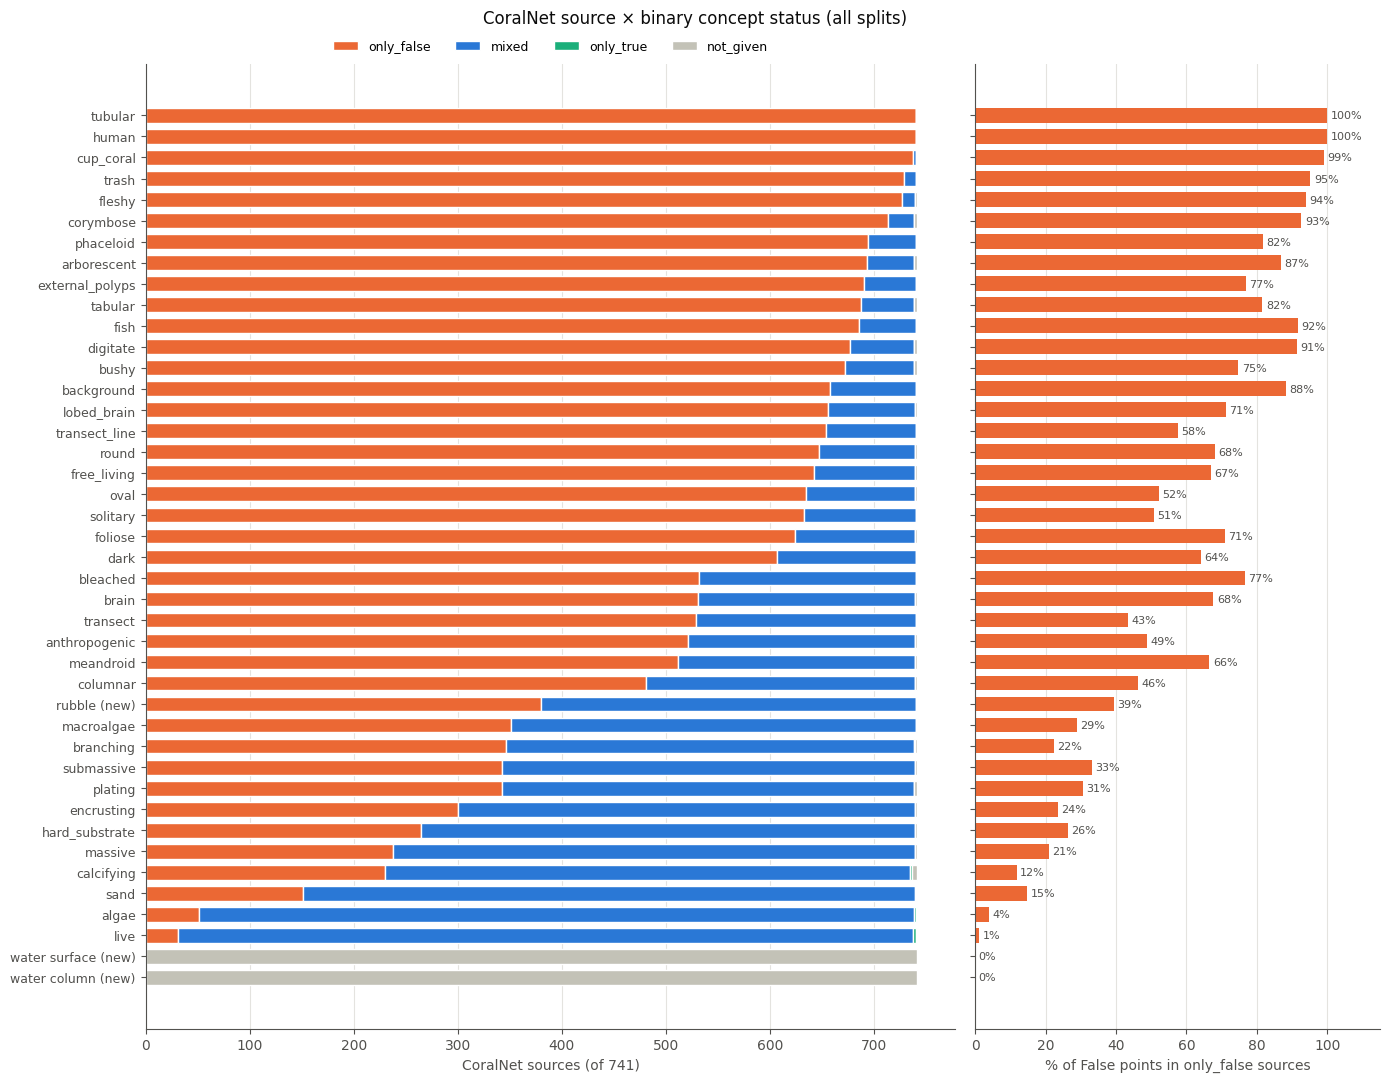

In [7]:
# Plot: sources per status for each concept, and the share of False points masking would remove
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
STATUS_COLORS = {"only_false": "#eb6834", "mixed": "#2a78d6", "only_true": "#1baf7a", "not_given": "#c3c2b7"}
pc = per_concept.sort_values(["only_false", "mixed"], ascending=[True, True])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 11), sharey=True, gridspec_kw={"width_ratios": [2, 1]})
y = np.arange(len(pc))
left = np.zeros(len(pc))
for status, color in STATUS_COLORS.items():
    v = pc[status].to_numpy()
    ax1.barh(y, v, left=left, color=color, height=0.7, edgecolor="white", linewidth=1, label=status)
    left += v
ax1.set_yticks(y, [c + ("" if pc.in_current_model[c] else " (new)") for c in pc.index], fontsize=9)
ax1.set_xlabel(f"CoralNet sources (of {mask.source_id.nunique()})", color=MUTED)
ax1.legend(frameon=False, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=9)
ax2.barh(y, pc.pct_false_masked.fillna(0), color=STATUS_COLORS["only_false"], height=0.7)
for yi, v in zip(y, pc.pct_false_masked.fillna(0)):
    ax2.text(v + 1, yi, f"{v:.0f}%", va="center", fontsize=8, color=MUTED)
ax2.set_xlim(0, 115)
ax2.set_xlabel("% of False points in only_false sources", color=MUTED)
for ax in (ax1, ax2):
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(MUTED); ax.spines["bottom"].set_color(MUTED); ax.tick_params(colors=MUTED)
fig.suptitle("CoralNet source × binary concept status (all splits)", fontsize=12, color=INK)
fig.tight_layout()

## only_true combinations

Sources where every annotated point is True for a concept. Usually the concept covers almost everything (e.g. a
source that only labels algae types), so these are worth a look rather than masking by default.

In [8]:
mask[mask.status == "only_true"].sort_values(["concept", "n_true"], ascending=[True, False])

,source_id,split,concept,in_current_model,status,n_true,n_false,n_not_given
10988,3722,train,algae,True,only_true,4700,0,29800
15692,4810,train,algae,True,only_true,1531,0,6105
11569,3857,test,branching,True,only_true,5,0,595
10999,3722,train,calcifying,True,only_true,239,0,34261
19722,5411,train,live,True,only_true,10386,0,11958
25812,6537,train,live,True,only_true,178,0,472
16530,4966,train,live,True,only_true,18,0,1982
1211,958,train,sand,True,only_true,197,0,1453


## Per source

In [9]:
per_source = pd.crosstab(mask.source_id, mask.status).reindex(
    columns=["only_false", "mixed", "only_true", "not_given"], fill_value=0)
per_source["split"] = source_split
per_source["points"] = n_points
per_source["labels"] = (sl > 0).sum(axis=1)
print("only_false concepts per source:")
print(per_source.only_false.describe().round(1).to_string())
per_source.sort_values("only_false", ascending=False).head(20)

only_false concepts per source:
count    741.0
mean      28.4
std        5.6
min        0.0
25%       25.0
50%       29.0
75%       33.0
max       39.0


status,only_false,mixed,only_true,not_given,split,points,labels
source_id,,,,,,,
6704,39,0,0,3,test,2880,5
958,39,0,1,2,train,1650,20
4364,39,1,0,2,train,2200,5
5255,39,1,0,2,test,4000,5
3807,39,1,0,2,test,1860,6
6965,38,2,0,2,train,110348,14
2074,38,2,0,2,train,6075,8
6583,38,2,0,2,train,4500,16
3785,38,2,0,2,train,11000,18


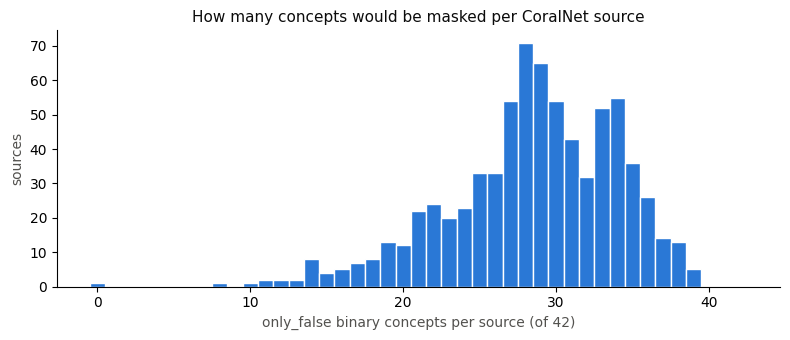

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(per_source.only_false, bins=np.arange(0, len(CONCEPTS) + 2) - 0.5, color="#2a78d6", edgecolor="white")
ax.set_xlabel(f"only_false binary concepts per source (of {len(CONCEPTS)})", color=MUTED)
ax.set_ylabel("sources", color=MUTED)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.set_title("How many concepts would be masked per CoralNet source", fontsize=11, color=INK)
fig.tight_layout()

## Train vs test

In [11]:
pd.crosstab([mask.concept], [mask.split, mask.status]).reindex(
    columns=pd.MultiIndex.from_product([["train", "test"], ["only_false", "mixed", "only_true", "not_given"]]),
    fill_value=0).loc[per_concept.sort_values("only_false", ascending=False).index]

train                                 test                          
                only_false mixed only_true not_given only_false mixed only_true not_given
concept                                                                                  
tubular                597     0         0         0        143     0         0         1
human                  597     0         0         0        143     0         0         1
cup_coral              596     1         0         0        141     2         0         1
trash                  590     7         0         0        139     4         0         1
fleshy                 586    10         0         1        141     2         0         1
corymbose              575    21         0         1        138     4         0         2
phaceloid              557    40         0         0        137     6         0         1
arborescent            565    31         0         1        128    14         0         2
external_polyps        555    42         0         0        135     8         0         1
tabular                556    40         0         1        131    11         0         2
fish                   554    43         0         0        132    11         0         1
digitate               540    56         0         1        137     5         0         2
bushy                  545    51         0         1        127    15         0         2
background             532    65         0         0        126    17         0         1
lobed_brain            526    70         0         1        130    13         0         1
transect_line          530    67         0         0        124    19         0         1
round                  514    82         0         1        133    10         0         1
free_living            512    84         0         1        130    13         0         1
oval                   505    91         0         1        130    13         0         1
solitary               505    92         0         0        128    15         0         1
foliose                500    96         0         1        124    19         0         1
dark                   485   112         0         0        122    21         0         1
bleached               431   166         0         0        101    42         0         1
brain                  435   161         0         1         96    47         0         1
transect               422   175         0         0        107    36         0         1
anthropogenic          414   182         0         1        107    36         0         1
meandroid              421   175         0         1         91    52         0         1
columnar               394   202         0         1         87    56         0         1
rubble                 297   300         0         0         83    60         0         1
macroalgae             283   314         0         0         68    75         0         1
branching              274   322         0         1         72    70         1         1
plating                286   310         0         1         56    86         0         2
submassive             265   331         0         1         77    66         0         1
encrusting             243   353         0         1         57    86         0         1
hard_substrate         215   382         0         0         50    92         0         2
massive                189   407         0         1         49    94         0         1
calcifying             186   407         1         3         44    98         0         2
sand                   114   482         1         0         37   106         0         1
algae                   37   558         2         0         14   129         0         1
live                    25   569         3         0          6   137         0         1
water column             0     0         0       597          0     0         0       144
water surface            0     0         0       597         

## Negatives left after masking (train splits)

Masking every only_false CoralNet source × concept pair removes those sources' False annotations from the loss. Which
concepts are then left with few or no negatives?

For every binary concept, over the **train** splits of all datasets, the True (positive) and False (negative)
annotations are split by origin:

- **cn_mixed**: CoralNet sources with both True and False for the concept (kept when masking);
- **cn_only_false**: CoralNet sources with only False (removed when masking);
- **other**: all non-CoralNet datasets (kept).

Annotations are points for sparse datasets; each dense mask (Coralscapes v2, UCSD mosaics, Benthos) that has the
concept True (or False) somewhere counts as 50, as in `Concept_Annotation_Coverage.ipynb`. Images with at least one
negative are counted too, since the loss also averages per image.

**Dropout** keeps each only_false negative with probability `p` instead of dropping it all. In expectation it keeps
`cn_mixed + other + p × cn_only_false` negatives.

In [12]:
DENSE_DATASETS = {"coralscapes_v2", "ucsd_mosaics", "benthos_yuval"}
DENSE_ANNOTATIONS_PER_MASK = 50
DROPOUT_KEEP = [0.0, 0.05, 0.1, 0.2, 1.0]  # 0 = full masking, 1 = no masking

allc = pd.read_parquet(LABEL_COUNTS)
tr = allc[allc.split == "train"].copy()
del allc
tr["image_key"] = tr.dataset + "/" + tr.image_id.astype(str)
tr["source_id"] = -1
is_cn = (tr.dataset == "coralnet").to_numpy()
tr.loc[is_cn, "source_id"] = tr.loc[is_cn, "image_id"].astype(str).map(
    cn.drop_duplicates("image_id").set_index(cn.drop_duplicates("image_id").image_id.astype(str)).source_id)
assert (tr.loc[is_cn, "source_id"] >= 0).all()

# Concept values (0 not_given, 1 False, 2 True) for every (dataset, label) key in the train data.
csv_all = pd.read_csv(CONCEPT_CSV)
csv_all["source_dataset_source"] = csv_all.source_dataset_source.astype(str).str.lower()
csv_all["source_label_class_name"] = csv_all.source_label_class_name.astype(str).str.lower()
csv_all = csv_all.drop_duplicates(["source_dataset_source", "source_label_class_name"]).set_index(
    ["source_dataset_source", "source_label_class_name"])


def key_values(d: str, l: str) -> list[int]:
    base = schema.row_for(d, l)[idx].astype(int).tolist()
    ext = []
    for c in extras:
        v = str(csv_all[c].get((d, l), "")).upper()
        ext.append(2 if v == "TRUE" else 1 if v == "FALSE" else 0)
    return base + ext


keys = tr[["dataset", "label"]].drop_duplicates().reset_index(drop=True)
KV = np.array([key_values(d, l) for d, l in keys.itertuples(index=False)], dtype=np.int8)
tr = tr.merge(keys.reset_index().rename(columns={"index": "key"}), on=["dataset", "label"])
vals = KV[tr.key.to_numpy()]  # (rows, concepts)

# only_false flag per row: CoralNet rows whose (source, concept) is only_false
of_tab = (mask[mask.split == "train"].assign(of=lambda d: d.status == "only_false")
          .pivot(index="source_id", columns="concept", values="of").reindex(columns=CONCEPTS).fillna(False))
of_rows = np.zeros(vals.shape, dtype=bool)
of_rows[is_cn] = of_tab.loc[tr.loc[is_cn, "source_id"].to_numpy()].to_numpy(dtype=bool)
dense = tr.dataset.isin(DENSE_DATASETS).to_numpy()
n = tr.n.to_numpy(dtype=np.float64)
print(f"train rows: {len(tr):,}; CoralNet train sources: {tr.loc[is_cn, 'source_id'].nunique()}")

train rows: 2,098,195; CoralNet train sources: 597


In [13]:
def ann_units(sel: np.ndarray) -> np.ndarray:
    # Annotation units per concept for the (rows x concepts) boolean selection `sel`:
    # sparse rows add their points, dense masks add 50 once per (image, concept).
    sparse_part = (sel & ~dense[:, None]).T.astype(np.float64) @ n
    if dense.any():
        d = pd.DataFrame(sel[dense], columns=CONCEPTS)
        d["img"] = tr.image_key.to_numpy()[dense]
        dense_part = d.groupby("img").any().sum().to_numpy() * DENSE_ANNOTATIONS_PER_MASK
    else:
        dense_part = 0
    return sparse_part + dense_part


def n_images(sel: np.ndarray) -> np.ndarray:
    d = pd.DataFrame(sel, columns=CONCEPTS)
    d["img"] = tr.image_key.to_numpy()
    return d.groupby("img").any().sum().to_numpy()


is_true, is_false = vals == 2, vals == 1
cn_rows = is_cn[:, None]
groups = {
    "pos": is_true,
    "neg_cn_mixed": is_false & cn_rows & ~of_rows,
    "neg_cn_only_false": is_false & of_rows,
    "neg_other": is_false & ~cn_rows,
}
neg = pd.DataFrame({k: ann_units(v) for k, v in groups.items()}, index=CONCEPTS).astype(np.int64)
neg["neg_total"] = neg.neg_cn_mixed + neg.neg_cn_only_false + neg.neg_other
neg["neg_after_mask"] = neg.neg_cn_mixed + neg.neg_other
neg["pct_neg_removed"] = (100 * neg.neg_cn_only_false / neg.neg_total.replace(0, np.nan)).round(1)
neg["neg_images_total"] = n_images(is_false)
neg["neg_images_after_mask"] = n_images(is_false & ~of_rows)
neg["pos_images"] = n_images(is_true)
n_cn_images = tr.loc[is_cn, "image_key"].nunique()
neg["cn_neg_images_before"] = n_images(is_false & cn_rows)
neg["cn_neg_images_after_mask"] = n_images(is_false & cn_rows & ~of_rows)
neg["pct_cn_images_with_neg_after_mask"] = (100 * neg.cn_neg_images_after_mask / n_cn_images).round(1)
neg["noncn_neg_images"] = n_images(is_false & ~cn_rows)
neg["cn_mixed_sources"] = of_tab.shape[0] - of_tab.sum().reindex(CONCEPTS).to_numpy() - \
    (mask[mask.split == "train"].pivot(index="source_id", columns="concept", values="status")
     .reindex(columns=CONCEPTS).isin(["not_given", "only_true"]).sum().to_numpy())
neg_by_ds = pd.DataFrame({ds: ann_units(is_false & (tr.dataset == ds).to_numpy()[:, None])
                          for ds in sorted(tr.dataset.unique()) if ds != "coralnet"}, index=CONCEPTS).astype(np.int64)
neg["other_datasets_with_neg"] = (neg_by_ds > 0).apply(lambda r: ", ".join(r.index[r]), axis=1)
neg["in_current_model"] = in_current_model
neg.sort_values("neg_after_mask")

,pos,neg_cn_mixed,neg_cn_only_false,neg_other,neg_total,neg_after_mask,pct_neg_removed,neg_images_total,neg_images_after_mask,pos_images,cn_neg_images_before,cn_neg_images_after_mask,pct_cn_images_with_neg_after_mask,noncn_neg_images,cn_mixed_sources,other_datasets_with_neg,in_current_model
water column,38350,0,0,97950,97950,97950,0.0,1959,1959,767,0,0,0.0,1959,0,coralscapes_v2,False
water surface,2750,0,0,98000,98000,98000,0.0,1960,1960,55,0,0,0.0,1960,0,coralscapes_v2,False
tubular,1,0,12630797,1860978,14491775,1860978,87.2,494185,35100,1,459085,0,0.0,35100,0,"catlin_seaview, coralscapes_v2, mermaid, moore...",True
human,8150,0,13268657,1954973,15223630,1954973,87.2,495936,35197,163,460739,0,0.0,35197,0,"catlin_seaview, coralscapes_v2, mermaid, moore...",True
cup_coral,1,112192,12518604,1860979,14491775,1973171,86.4,494185,42054,1,459085,6954,1.5,35100,1,"catlin_seaview, coralscapes_v2, mermaid, moore...",True
fleshy,2632,733070,11346782,1488651,13568503,2221721,83.6,492493,108342,811,457763,73612,15.9,34730,10,"catlin_seaview, coralscapes_v2, mermaid, moore...",True
corymbose,211722,902189,10541723,1408660,12852572,2310849,82.0,491053,61881,9110,456278,27106,5.8,34775,21,"catlin_seaview, coralscapes_v2, mermaid, moore...",True
digitate,21310,964727,10489367,1417576,12871670,2382303,81.5,491135,68500,3771,456345,33710,7.3,34790,56,"catlin_seaview, coralscapes_v2, mermaid, moore...",True
trash,2820,437917,12830639,1954804,15223360,2392721,84.3,495936,43394,109,460739,8197,1.8,35197,7,"catlin_seaview, coralscapes_v2, mermaid, moore...",True
fish,90845,931602,12335814,1954169,15221585,2885771,81.0,495936,59386,3052,460739,24189,5.2,35197,43,"catlin_seaview, coralscapes_v2, mermaid, moore...",True


### Concepts left with no or very few negatives

`neg_to_pos_after_mask` is negatives per positive after full masking. A concept whose negatives drop to zero (or far
below its positives) can only learn "present"; with nothing pushing it down the model is likely to predict it
everywhere.

In [14]:
neg["neg_to_pos_before"] = (neg.neg_total / neg.pos.replace(0, np.nan)).round(2)
neg["neg_to_pos_after_mask"] = (neg.neg_after_mask / neg.pos.replace(0, np.nan)).round(2)
cols = ["in_current_model", "pos", "neg_total", "neg_after_mask", "pct_neg_removed", "neg_to_pos_before",
        "neg_to_pos_after_mask", "cn_neg_images_after_mask", "pct_cn_images_with_neg_after_mask",
        "noncn_neg_images", "cn_mixed_sources", "other_datasets_with_neg"]
flag = neg[(neg.neg_after_mask == 0) | (neg.neg_to_pos_after_mask < 1) | (neg.pos == 0)]
print(f"{len(flag)} concepts with no negatives, fewer negatives than positives, or no positives after masking")
flag[cols].sort_values("neg_to_pos_after_mask")

0 concepts with no negatives, fewer negatives than positives, or no positives after masking


,in_current_model,pos,neg_total,neg_after_mask,pct_neg_removed,neg_to_pos_before,neg_to_pos_after_mask,cn_neg_images_after_mask,pct_cn_images_with_neg_after_mask,noncn_neg_images,cn_mixed_sources,other_datasets_with_neg


In [15]:
neg[cols].sort_values("neg_to_pos_after_mask")

,in_current_model,pos,neg_total,neg_after_mask,pct_neg_removed,neg_to_pos_before,neg_to_pos_after_mask,cn_neg_images_after_mask,pct_cn_images_with_neg_after_mask,noncn_neg_images,cn_mixed_sources,other_datasets_with_neg
algae,True,7436378,8042552,7750459,3.6,1.08,1.04,389662,84.1,34777,558,"catlin_seaview, coralscapes_v2, mermaid, moore..."
water column,False,38350,97950,97950,0.0,2.55,2.55,0,0.0,1959,0,coralscapes_v2
live,True,3539925,11985305,11870813,1.0,3.39,3.35,448420,96.7,34097,569,"catlin_seaview, coralscapes_v2, mermaid, moore..."
sand,True,1888070,13390871,11759420,12.2,7.09,6.23,415083,89.5,35001,482,"catlin_seaview, coralscapes_v2, mermaid, moore..."
hard_substrate,True,865287,8739446,6819220,22.0,10.10,7.88,353401,76.2,35154,382,"catlin_seaview, coralscapes_v2, mermaid, moore..."
calcifying,True,1330430,12234054,11014902,10.0,9.20,8.28,411407,88.7,35003,407,"catlin_seaview, coralscapes_v2, mermaid, moore..."
rubble,False,758507,9836839,6545634,33.5,12.97,8.63,303154,65.4,35110,300,"catlin_seaview, coralscapes_v2, mermaid, moore..."
massive,True,994941,12705862,10461559,17.7,12.77,10.51,397827,85.8,34757,407,"catlin_seaview, coralscapes_v2, mermaid, moore..."
branching,True,954389,12629129,10243643,18.9,13.23,10.73,386274,83.3,34746,322,"catlin_seaview, coralscapes_v2, mermaid, moore..."
macroalgae,True,916279,13677716,9944750,27.3,14.93,10.85,389927,84.1,35072,314,"catlin_seaview, coralscapes_v2, mermaid, moore..."


### Do CoralNet images still get negatives?

Every concept keeps negatives from the non-CoralNet datasets, but those come from other image domains (Catlin
Seaview, MERMAID, Moorea, Coralscapes, UCSD). The table shows, per concept, the share of CoralNet **train images**
that still have at least one negative after full masking, and how many CoralNet images dropout with `p` would give in
expectation (per image: kept if any of its only_false negatives survives is approximated by `p` per image).

In [16]:
cn_img = neg[["pos_images", "cn_neg_images_before", "cn_neg_images_after_mask", "pct_cn_images_with_neg_after_mask",
              "noncn_neg_images", "cn_mixed_sources"]].copy()
masked_cn_imgs = cn_img.cn_neg_images_before - cn_img.cn_neg_images_after_mask
for p in [0.05, 0.1, 0.2]:
    cn_img[f"cn_neg_images p={p}"] = (cn_img.cn_neg_images_after_mask + p * masked_cn_imgs).round().astype(np.int64)
print(f"CoralNet train images: {n_cn_images:,}")
cn_img.sort_values("cn_neg_images_after_mask")

CoralNet train images: 463,597


,pos_images,cn_neg_images_before,cn_neg_images_after_mask,pct_cn_images_with_neg_after_mask,noncn_neg_images,cn_mixed_sources,cn_neg_images p=0.05,cn_neg_images p=0.1,cn_neg_images p=0.2
tubular,1,459085,0,0.0,35100,0,22954,45908,91817
water column,767,0,0,0.0,1959,0,0,0,0
water surface,55,0,0,0.0,1960,0,0,0,0
human,163,460739,0,0.0,35197,0,23037,46074,92148
cup_coral,1,459085,6954,1.5,35100,1,29561,52167,97380
trash,109,460739,8197,1.8,35197,7,30824,53451,98705
fish,3052,460739,24189,5.2,35197,43,46016,67844,111499
corymbose,9110,456278,27106,5.8,34775,21,48565,70023,112940
bushy,2169,455334,31182,6.7,34542,51,52390,73597,116012
digitate,3771,456345,33710,7.3,34790,56,54842,75974,118237


### Dropout: keep a share `p` of the only_false negatives

Expected negatives and negatives per positive for `p` in `DROPOUT_KEEP` (p = 0 is full masking, p = 1 is no masking).

In [17]:
drop = pd.DataFrame({f"neg p={p}": (neg.neg_after_mask + p * neg.neg_cn_only_false).round().astype(np.int64)
                     for p in DROPOUT_KEEP})
ratio = pd.DataFrame({f"neg/pos p={p}": ((neg.neg_after_mask + p * neg.neg_cn_only_false)
                                         / neg.pos.replace(0, np.nan)).round(2) for p in DROPOUT_KEEP})
dropout_table = pd.concat([neg[["pos"]], drop, ratio], axis=1).sort_values(f"neg/pos p={DROPOUT_KEEP[0]}")
dropout_table

,pos,neg p=0.0,neg p=0.05,neg p=0.1,neg p=0.2,neg p=1.0,neg/pos p=0.0,neg/pos p=0.05,neg/pos p=0.1,neg/pos p=0.2,neg/pos p=1.0
algae,7436378,7750459,7765064,7779668,7808878,8042552,1.04,1.04,1.05,1.05,1.08
water column,38350,97950,97950,97950,97950,97950,2.55,2.55,2.55,2.55,2.55
live,3539925,11870813,11876538,11882262,11893711,11985305,3.35,3.36,3.36,3.36,3.39
sand,1888070,11759420,11840993,11922565,12085710,13390871,6.23,6.27,6.31,6.40,7.09
hard_substrate,865287,6819220,6915231,7011243,7203265,8739446,7.88,7.99,8.10,8.32,10.10
calcifying,1330430,11014902,11075860,11136817,11258732,12234054,8.28,8.33,8.37,8.46,9.20
rubble,758507,6545634,6710194,6874754,7203875,9836839,8.63,8.85,9.06,9.50,12.97
massive,994941,10461559,10573774,10685989,10910420,12705862,10.51,10.63,10.74,10.97,12.77
branching,954389,10243643,10362917,10482192,10720740,12629129,10.73,10.86,10.98,11.23,13.23
macroalgae,916279,9944750,10131398,10318047,10691343,13677716,10.85,11.06,11.26,11.67,14.93


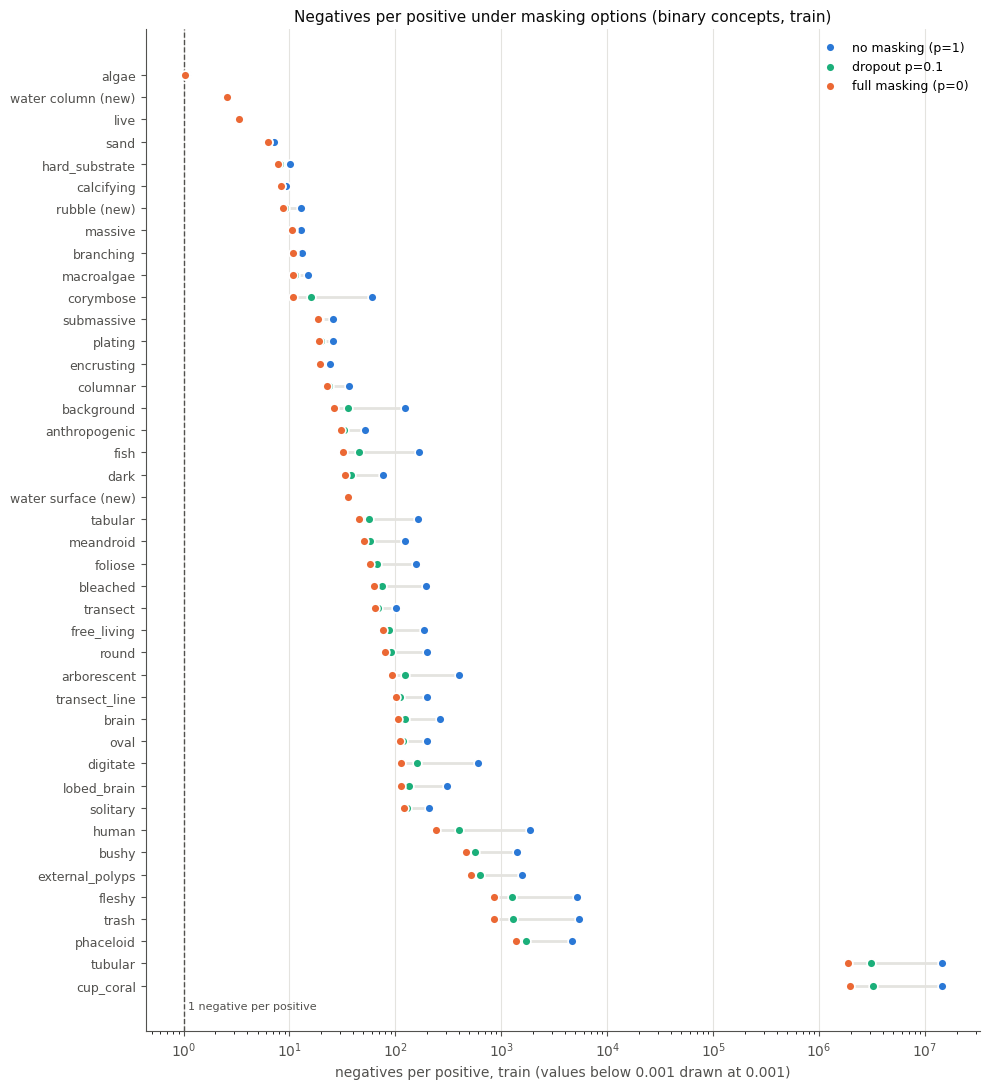

In [18]:
# Dot plot: negatives per positive (log scale) for no masking, dropout p = 0.1, and full masking
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SER = [("no masking (p=1)", 1.0, "#2a78d6"), ("dropout p=0.1", 0.1, "#1baf7a"), ("full masking (p=0)", 0.0, "#eb6834")]
plot_df = neg[neg.pos > 0].copy()
plot_df["r0"] = (plot_df.neg_after_mask / plot_df.pos)
plot_df = plot_df.sort_values("r0", ascending=False)
yy = np.arange(len(plot_df))
fig, ax = plt.subplots(figsize=(10, 11))
floor = 1e-3
for label, p, color in SER:
    r = (plot_df.neg_after_mask + p * plot_df.neg_cn_only_false) / plot_df.pos
    ax.scatter(np.maximum(r, floor), yy, s=40, color=color, edgecolor="white", linewidth=1.2, label=label, zorder=3)
for yi, (_, row) in zip(yy, plot_df.iterrows()):
    lo = max(row.neg_after_mask / row.pos, floor)
    hi = row.neg_total / row.pos
    ax.plot([lo, hi], [yi, yi], color=GRID, lw=2, zorder=1)
ax.axvline(1, color=MUTED, ls="--", lw=1)
ax.text(1.1, -0.9, "1 negative per positive", fontsize=8, color=MUTED, va="center")
ax.set_xscale("log")
ax.set_yticks(yy, [c + ("" if plot_df.in_current_model[c] else " (new)") for c in plot_df.index], fontsize=9)
ax.set_xlabel(f"negatives per positive, train (values below {floor} drawn at {floor})", color=MUTED)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color(MUTED); ax.spines["bottom"].set_color(MUTED); ax.tick_params(colors=MUTED)
ax.grid(axis="x", color=GRID, lw=0.8, which="major"); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9, loc="upper right")
ax.set_title("Negatives per positive under masking options (binary concepts, train)", fontsize=11, color=INK)
fig.tight_layout()

In [19]:
# Concepts with no positives at all in train: masking leaves them with no signal in either direction
neg.loc[neg.pos == 0, ["in_current_model", "neg_total", "neg_after_mask", "other_datasets_with_neg"]]

,in_current_model,neg_total,neg_after_mask,other_datasets_with_neg


## Export

One row per (CoralNet source, binary concept). Training code can mask the concept for a source where
`status == "only_false"` (and optionally `"only_true"`).

In [20]:
mask.to_parquet(MASK_OUT, index=False)
print(f"Wrote {MASK_OUT.relative_to(REPO)}: {len(mask):,} rows")
print(mask.groupby(["split", "status"]).size().unstack(fill_value=0))

Wrote dataset_stats/coralnet_source_concept_mask.parquet: 31,122 rows
status  mixed  not_given  only_false  only_true
split                                          
test     1590        336        4121          1
train    6897       1217       16953          7
